# 1 · Grafo sin modelo

**Módulo 1 · Introducción.** El proyecto del módulo es un agente de cálculo simbólico. Esta lección construye su base sin modelo de lenguaje. Corre en CPU, sin GPU ni claves.

La lección parte de una observación: un algoritmo ya es un grafo. Sus variables forman un estado, cada bloque de instrucciones transforma ese estado y cada condición elige el bloque siguiente. LangGraph escribe esa estructura de forma explícita. Primero se traduce el algoritmo de Euclides del código a un diagrama de flujo, y del diagrama de flujo a LangGraph. Con ese ejemplo se definen las piezas de un grafo (esquema, estado, nodo, reducer y arista) y su ejecución por supersteps. Después, el método de Newton usa el mismo grafo con otro nodo, y con él aparece la pregunta de cuándo termina una ejecución.

Requisito: `pip install "langgraph>=1.2"`. Las salidas de este notebook son de langgraph 1.2.17.

In [1]:
from importlib.metadata import version

print("langgraph", version("langgraph"))

langgraph 1.2.17


## 1. Un algoritmo es un grafo

El algoritmo de Euclides calcula el máximo común divisor de dos naturales con una sola regla: si $b > 0$, entonces $\gcd(a, b) = \gcd(b,\, a \bmod b)$, y además $\gcd(a, 0) = a$. Mientras $b \ne 0$, el par $(a, b)$ se reemplaza por $(b,\, a \bmod b)$:

In [2]:
def mcd(a: int, b: int) -> int:
    while b != 0:
        a, b = b, a % b
    return a


mcd(1071, 462)

21

El programa tiene tres clases de piezas: las variables `a` y `b`, que guardan los datos; la asignación `a, b = b, a % b`, que los cambia; y la condición `b != 0`, que decide si la asignación se repite o el programa termina. Un **diagrama de flujo** dibuja esas piezas: una caja por cada bloque de instrucciones, un rombo por cada condición y una flecha por cada forma de seguir. Ejecutar el programa es recorrer el diagrama: cada caja cambia los valores de las variables y cada rombo los lee para elegir la flecha.

<img src="../../imagenes/diagramas/modulo-1/euclides-flujo.svg" alt="A la izquierda, el código de mcd línea por línea; a la derecha, su diagrama de flujo: inicio, el rombo b ≠ 0, la caja a, b ← b, a mod b que vuelve al rombo, y fin. La ejecución con (1071, 462) enciende a la vez la línea y la pieza del diagrama, y la memoria pasa por (1071, 462), (462, 147), (147, 21) y (21, 0) hasta devolver 21" width="720">

**Definición 1.1 (memoria).** Sea $X$ un conjunto finito de variables, con un conjunto de valores $D_x$ para cada $x \in X$. Una memoria es una función $\sigma$ que asigna a cada variable $x \in X$ un valor $\sigma(x) \in D_x$. $\Sigma$ denota el conjunto de memorias.

Para Euclides, $X = \{a, b\}$ y $D_a = D_b = \mathbb{N}$. La memoria inicial es $\sigma_0 = \{a \mapsto 1071,\ b \mapsto 462\}$.

**Definición 1.2 (diagrama de flujo).** Un diagrama de flujo es un grafo dirigido finito con un vértice de inicio, un vértice de fin y dos clases de vértices intermedios:

- **bloques**, cada uno con un conjunto $A \subseteq X$ de variables que asigna, una función $T : \Sigma \to \Sigma$ que solo cambia esas variables, es decir, $T(\sigma)(x) = \sigma(x)$ si $x \notin A$, y una flecha de salida;
- **decisiones**, cada una con un predicado $p : \Sigma \to \{\mathsf{V}, \mathsf{F}\}$ y dos flechas de salida, una para cada valor.

El inicio tiene una flecha de salida y ninguna de entrada, y el fin no tiene flechas de salida. Basta que cada $T$ esté definida en las memorias con que la ejecución puede llegar al bloque.

Para escribir los bloques, $\sigma[x \mapsto v,\ y \mapsto w]$ denota la memoria que coincide con $\sigma$ salvo en $x$ y en $y$, donde toma los valores $v$ y $w$. El bloque de Euclides asigna $A = \{a, b\}$ y cambia las dos variables a la vez,

$$T(\sigma) = \sigma\big[a \mapsto \sigma(b),\ b \mapsto \sigma(a) \bmod \sigma(b)\big],$$

y su decisión es $p(\sigma) = \mathsf{V}$ si y solo si $\sigma(b) \ne 0$. $T$ no está definida si $\sigma(b) = 0$, pero el rombo impide llegar a la caja con esa memoria.

**Definición 1.3 (ejecución).** Una ejecución desde una memoria $\sigma_0$ recorre el diagrama a partir del inicio. Al pasar por un bloque, la memoria $\sigma$ pasa a ser $T(\sigma)$; al pasar por una decisión, la memoria no cambia y se sigue la flecha del valor $p(\sigma)$. La ejecución termina si llega al fin.

Si $v_t$ es el $t$-ésimo bloque recorrido, la ejecución produce la sucesión de memorias $\sigma_0, \sigma_1, \sigma_2, \dots$ con $\sigma_t = T_{v_t}(\sigma_{t-1})$: la memoria al salir de cada bloque. Euclides tiene un solo bloque, así que la sucesión es la de los pares $(a, b)$ después de cada vuelta:

In [3]:
def mcd_con_traza(a: int, b: int) -> list[tuple[int, int]]:
    traza = [(a, b)]
    while b != 0:
        a, b = b, a % b
        traza.append((a, b))
    return traza


mcd_con_traza(1071, 462)

[(1071, 462), (462, 147), (147, 21), (21, 0)]

El algoritmo **itera**: aplica el mismo bloque a la memoria que dejó la vuelta anterior, y el rombo decide cuándo parar. Aquí hay tres vueltas. La última memoria tiene $b = 0$, así que el rombo elige el fin y el resultado es $a = 21$.

**Las tres formas de control.** Euclides usa una sola forma de control, la iteración. Un programa estructurado combina tres:

- **secuencia**: un bloque después de otro;
- **selección** (`if`): una decisión con un camino para cada valor, que después se juntan;
- **iteración** (`while`): una decisión cuya flecha $\mathsf{V}$ pasa por un bloque y vuelve a la misma decisión.

Cada forma es un pedazo de diagrama de flujo, y encadenarlas da el diagrama de cualquier programa estructurado. El teorema siguiente dice que limitarse a estas tres formas no deja nada afuera.

**Teorema (Böhm–Jacopini, 1966; resultado clásico).** Toda función que calcula un diagrama de flujo la calcula también un diagrama construido solo con secuencia, selección e iteración, agregando si hace falta variables booleanas a la memoria.

La referencia es C. Böhm y G. Jacopini, *Flow diagrams, Turing machines and languages with only two formation rules*, Communications of the ACM, 1966. Así, ver un algoritmo como un grafo no depende del ejemplo. Un algoritmo que trabaja sobre variables se dibuja como un diagrama de flujo, porque la Definición 1.2 admite bloques y decisiones arbitrarios, y el teorema dice que con las tres formas se arma cualquiera de esos diagramas. En los dos casos el resultado es un grafo dirigido cuyos vértices transforman o leen una memoria. La sección siguiente traduce ese grafo a LangGraph.

## 2. Del diagrama de flujo a LangGraph

Un grafo de LangGraph es un diagrama de flujo escrito con objetos de Python. Las piezas son las mismas, con otros nombres:

- la memoria se llama **estado**, y sus variables son las **claves** de un esquema;
- un bloque se llama **nodo**: una función de Python que recibe el estado y devuelve los valores nuevos de las claves que cambia;
- la flecha que sale de un vértice se llama **arista**. Si la flecha llega a un rombo, la arista es **condicional**: una función que lee el estado y devuelve el nombre del vértice siguiente;
- el inicio y el fin se llaman `START` y `END`.

Solo cambia el lugar de las decisiones. En el diagrama de flujo una decisión es un vértice, el rombo. LangGraph no tiene rombos: la decisión se evalúa en la arista, al salir de un nodo o de `START`. La figura recorre el algoritmo de Euclides en las tres formas, pieza por pieza:

<img src="../../imagenes/diagramas/modulo-1/euclides-paralelo.svg" alt="Tres columnas: el programa mcd, su diagrama de flujo y el grafo de LangGraph con START, paso y END. Cada paso enciende la misma pieza en las tres: las variables a, b con la memoria y el esquema EstadoMCD; la llamada mcd(1071, 462) con el inicio y START; la asignación con la caja y el nodo paso; la condición b != 0 con el rombo y la arista condicional c, que sale de START y de paso; y return a con el fin y END" width="860">

El grafo de la tercera columna, en código:

In [4]:
from typing_extensions import TypedDict

from langgraph.graph import END, START, StateGraph


class EstadoMCD(TypedDict):
    a: int
    b: int


def paso(s: EstadoMCD) -> dict:
    """La caja: a, b ← b, a mod b."""
    return {"a": s["b"], "b": s["a"] % s["b"]}


def continuar(s: EstadoMCD) -> str:
    """El rombo: sigue con paso mientras b ≠ 0."""
    return "paso" if s["b"] != 0 else END


constructor = StateGraph(EstadoMCD)
constructor.add_node("paso", paso)
constructor.add_conditional_edges(START, continuar, ["paso", END])
constructor.add_conditional_edges("paso", continuar, ["paso", END])
euclides = constructor.compile()

euclides.invoke({"a": 1071, "b": 462})

{'a': 21, 'b': 0}

El tercer argumento de `add_conditional_edges` dice a qué vértices puede ir la arista (sección 6), e `invoke` ejecuta el grafo con una entrada y devuelve el estado final.

Pieza por pieza:

| Programa | Diagrama de flujo | LangGraph |
|---|---|---|
| variables `a`, `b` | memoria | esquema `EstadoMCD`; el estado es un `dict` |
| llamada `mcd(1071, 462)` | inicio | `START`, con la entrada `{"a": 1071, "b": 462}` |
| `a, b = b, a % b` | caja | nodo `paso` |
| `while b != 0` | rombo | arista condicional $c$ (`continuar`), desde `START` y desde `paso` |
| `return a` | fin | `END`; `invoke` devuelve el estado final completo, y el resultado es su clave `a` |
| una vuelta del `while` | un paso por la caja | un superstep (sección 7) |

La arista condicional aparece dos veces porque al rombo llegan dos flechas: la del inicio y la que vuelve de la caja. La sección 6 explica por qué la que sale de `START` no puede ser una arista fija.

Las tres formas de control también se traducen. La secuencia da aristas fijas; la selección, una arista condicional; y la iteración, una arista condicional que vuelve al nodo del que sale:

<img src="../../imagenes/diagramas/modulo-1/tres-formas.svg" alt="Tres filas, secuencia, selección e iteración, en tres columnas: programa, diagrama de flujo y LangGraph. La secuencia y = x + 1, z = 2 * y es una cadena de cajas y la cadena START → sumar → duplicar → END. El if x &lt; 0 es un rombo y una arista condicional desde START a negar o a END. El while b != 0 es un rombo con una caja que vuelve a él, y en LangGraph las aristas condicionales desde START y desde paso, con el lazo paso → paso. Los rombos y las aristas condicionales tienen el mismo color" width="760">

**Mapa de las secciones 3 a 7.** Un superstep del grafo `euclides`, con los valores de la primera vuelta. Cada pieza se define en la sección que indica el diagrama: el estado (§3), el nodo y la actualización (§4), el reducer (§5), la arista condicional (§6) y el superstep (§7).

<img src="../../imagenes/diagramas/modulo-1/superstep.svg" alt="Un superstep: el estado s₀ = {a: 1071, b: 462} entra al nodo paso, que devuelve la actualización u = {a: 462, b: 147}; el reducer da s₁ = s₀ ⊕ u, y la arista c evalúa s₁ y vuelve a paso si b ≠ 0 o va a END si b = 0" width="760">

## 3. Esquema y estado

**Definición 1.4 (esquema).** Un esquema es un conjunto finito de claves $K$ junto con un conjunto de valores $V_k$ para cada clave $k \in K$.

**Definición 1.5 (estado).** Un estado es una función $s$ que asigna a cada clave $k \in K$ un valor $s(k) \in V_k$. El conjunto de estados es $S = \prod_{k \in K} V_k$.

Son la memoria de la Definición 1.1 con otro nombre: las claves son las variables y $S$ es $\Sigma$. El esquema es un tipo y un estado es un elemento de ese tipo. En LangGraph, el esquema se declara con un `TypedDict`: cada atributo es una clave y su anotación indica $V_k$. Un estado es un `dict` con esas claves. Para Euclides, $K = \{a, b\}$ con $V_a = V_b = \mathbb{N}$, y el esquema es el `EstadoMCD` de la sección 2.

**Observación.** La anotación documenta $V_k$, pero no se verifica: un `TypedDict` no valida tipos al ejecutar, y un nodo podría escribir un texto en `a` sin que nada falle. Tampoco distingue $\mathbb{N}$ de $\mathbb{Z}$, porque `int` admite negativos. Y no se exige que la entrada tenga todas las claves: una clave ausente no existe en el estado hasta que algo la escribe, y leerla en un nodo lanza `KeyError`. El módulo 2 usa Pydantic para validar.

## 4. Nodos y actualizaciones

**Definición 1.6 (actualización).** Una actualización es una función parcial $u$ de $K$ en $\bigcup_{k \in K} V_k$, con $u(k) \in V_k$ para cada $k \in \operatorname{dom}(u)$. $U$ denota el conjunto de actualizaciones.

**Definición 1.7 (nodo).** Un nodo es una función $\varphi : S \to U$. Recibe el estado completo y devuelve solo las claves que actualiza.

Un bloque $T$ del diagrama de flujo da un nodo: $\varphi(s)$ es $T(s)$ restringida a las variables que el bloque asigna. Para Euclides,

$$\varphi(s) = \{a \mapsto s(b),\ b \mapsto s(a) \bmod s(b)\},$$

que es la función `paso` de la sección 2. En Python, un nodo es una función que recibe el `dict` del estado y devuelve un `dict` con algunas de sus claves:

In [5]:
s = {"a": 1071, "b": 462}
print(paso(s))
print(s)

{'a': 462, 'b': 147}
{'a': 1071, 'b': 462}


El nodo no modifica `s`: devuelve una actualización nueva, y LangGraph la aplica.

**Observación (asignación simultánea).** Los dos valores de $\varphi(s)$ se calculan con el mismo estado $s$, y ninguno ve al otro. Por eso `paso` es la asignación simultánea `a, b = b, a % b` y no la secuencia `a = b` seguida de `b = a % b`, cuya segunda instrucción ya vería el `a` nuevo y daría $b \bmod b = 0$. El ejercicio 6 parte la caja en dos nodos y muestra el efecto.

## 5. Reducers: cómo se aplica una actualización

**Definición 1.8 (reducer).** Un reducer para la clave $k$ es una función $r_k : V_k \times V_k \to V_k$. Aplicar una actualización $u$ a un estado $s$ da el estado $s \oplus u$ definido por

$$(s \oplus u)(k) = \begin{cases} r_k\big(s(k),\, u(k)\big) & \text{si } k \in \operatorname{dom}(u), \\ s(k) & \text{si } k \notin \operatorname{dom}(u). \end{cases}$$

**Propiedad 1.9.** Si una clave no declara reducer, $r_k(v, w) = w$: el valor nuevo reemplaza al anterior. Las claves fuera de $\operatorname{dom}(u)$ no cambian.

Con reducers de reemplazo, $s \oplus u$ es la notación de la sección 1: $s \oplus \{a \mapsto v,\ b \mapsto w\} = s[a \mapsto v,\ b \mapsto w]$. En particular, $s \oplus \varphi(s) = T(s)$: aplicar la actualización del nodo da lo mismo que pasar por la caja.

**Observación.** En este módulo el valor de la actualización está en el mismo conjunto $V_k$. En general, un reducer puede recibir como segundo argumento algo de otro tipo; `add_messages`, en la lección 2, acepta un mensaje suelto o una lista.

Se comprueba con un grafo de un nodo que devuelve solo `a`. Sus aristas son fijas, porque `START → solo_a → END` es una secuencia sin rombos:

In [6]:
def solo_a(s: EstadoMCD) -> dict:
    return {"a": 7}


constructor = StateGraph(EstadoMCD)
constructor.add_node("solo_a", solo_a)
constructor.add_edge(START, "solo_a")
constructor.add_edge("solo_a", END)
un_nodo = constructor.compile()

un_nodo.invoke({"a": 1071, "b": 462})

{'a': 7, 'b': 462}

`b` conserva su valor porque no está en el dominio de la actualización.

Un reducer se declara con `Annotated[V_k, r_k]`. Con `operator.add`, que en listas es la concatenación, la clave acumula en lugar de reemplazar. En Euclides se pueden acumular los cocientes $\lfloor a_{t-1} / b_{t-1} \rfloor$ de cada división. Esa lista es la fracción continua de $a_0 / b_0$; para la entrada de esta lección,

$$\frac{1071}{462} = 2 + \dfrac{1}{3 + \dfrac{1}{7}} = [2; 3, 7].$$

In [7]:
import operator
from typing import Annotated


class EstadoConCocientes(TypedDict):
    a: int
    b: int
    cocientes: Annotated[list[int], operator.add]


def paso_con_cociente(s: EstadoConCocientes) -> dict:
    a, b = s["a"], s["b"]
    return {"a": b, "b": a % b, "cocientes": [a // b]}


constructor = StateGraph(EstadoConCocientes)
constructor.add_node("paso", paso_con_cociente)
constructor.add_conditional_edges(START, continuar, ["paso", END])
constructor.add_conditional_edges("paso", continuar, ["paso", END])
con_cocientes = constructor.compile()

con_cocientes.invoke({"a": 1071, "b": 462, "cocientes": []})

{'a': 21, 'b': 0, 'cocientes': [2, 3, 7]}

`continuar` sirve sin cambios, porque solo lee `b`. Arriba, la actualización de `solo_a`; abajo, la del segundo superstep de `con_cocientes`, clave por clave:

<img src="../../imagenes/diagramas/modulo-1/reducer.svg" alt="Arriba, s = {a: 1071, b: 462} más u = {a: 7} da {a: 7, b: 462}: a se reemplaza y b se conserva. Abajo, s = {a: 462, b: 147, cocientes: [2]} más u = {a: 147, b: 21, cocientes: [3]} da {a: 147, b: 21, cocientes: [2, 3]}: a y b se reemplazan y los cocientes se concatenan" width="720">

Internamente, cada clave del esquema es un **canal**, y el tipo de canal implementa su reducer: `LastValue` reemplaza y `BinaryOperatorAggregate` aplica $r_k$.

In [8]:
{
    clave: type(canal).__name__
    for clave, canal in con_cocientes.channels.items()
    if clave in EstadoConCocientes.__annotations__
}

{'a': 'LastValue', 'b': 'LastValue', 'cocientes': 'BinaryOperatorAggregate'}

## 6. Aristas y grafo

**Definición 1.10 (grafo).** Un grafo es un par $G = (V, E)$. $V$ contiene los nodos y dos vértices especiales, `START` y `END`. Una arista es de uno de dos tipos:

- **fija**, un par $(v, w)$ con $v \ne \texttt{END}$ y $w \ne \texttt{START}$: después de $v$ se ejecuta $w$;
- **condicional** desde $v$, una función $c : S \to V \setminus \{\texttt{START}\}$: evaluada en el estado que deja $v$, elige el vértice siguiente.

La ejecución parte en `START` y termina cuando no queda ningún nodo activo. En los grafos de esta lección, eso ocurre al llegar a `END`.

**De rombos a aristas.** Una decisión del diagrama de flujo no es un vértice de $G$. Se traduce siguiendo las flechas: desde cada vértice que no es una decisión se avanza por su flecha de salida y, en cada rombo que aparece, por la flecha que indica su predicado, hasta llegar a una caja o al fin.

**Construcción 1.11 (de diagrama de flujo a grafo).** Dado un diagrama de flujo con variables $X$, el grafo $G$ tiene:

1. el esquema $K = X$, sin reducers;
2. un nodo $\varphi_w$ por cada bloque $w$, con $\varphi_w(s)$ igual a $T_w(s)$ restringida a $A_w$, las variables que asigna $w$;
3. una arista desde `START` y una desde cada nodo $v$: $c_v(s)$ es el vértice al que se llega desde $v$ siguiendo las flechas con la memoria $s$, y `END` si se llega al fin. Si el camino no pasa por rombos, $c_v$ es constante y la arista es fija.

Se supone que ningún ciclo del diagrama pasa solo por rombos. Los rombos no cambian la memoria, así que, si el camino desde $v$ volviera a un rombo, se repetiría para siempre sin llegar a una caja; con esa hipótesis visita cada rombo a lo más una vez y $c_v$ está bien definida.

Para Euclides, al rombo $b \ne 0$ llegan dos flechas, desde el inicio y desde la caja, y las dos se convierten en la misma arista condicional:

$$c_{\texttt{START}}(s) = c_{\texttt{paso}}(s) = \begin{cases} \texttt{paso} & \text{si } s(b) \ne 0, \\ \texttt{END} & \text{si no.} \end{cases}$$

Es `continuar`, y por eso el grafo de la sección 2 la agrega dos veces.

**`while` y `do … while`.** La arista que sale de `START` tiene que ser condicional. Con la arista fija `START → paso`, el nodo correría una vez antes de evaluar la condición. Ese es el ciclo `do … while`, que primero ejecuta el cuerpo y después pregunta, y para Euclides con $b_0 = 0$ significa dividir por cero:

<img src="../../imagenes/diagramas/modulo-1/while-do-while.svg" alt="Arriba, el while: dos flechas entran al rombo b ≠ 0, desde el inicio y desde la caja, y en LangGraph la arista condicional c sale de START y de paso. Abajo, el do … while: el inicio va directo a la caja y el rombo está después; en LangGraph es la arista fija START → paso, que con b₀ = 0 calcula a % 0 y lanza ZeroDivisionError" width="760">

In [9]:
constructor = StateGraph(EstadoMCD)
constructor.add_node("paso", paso)
constructor.add_edge(START, "paso")  # do … while: paso corre antes de preguntar
constructor.add_conditional_edges("paso", continuar, ["paso", END])
hacer_mientras = constructor.compile()

print("while:   ", euclides.invoke({"a": 5, "b": 0}))
try:
    hacer_mientras.invoke({"a": 5, "b": 0})
except ZeroDivisionError as error:
    print("do-while:", type(error).__name__, "→", error)

while:    {'a': 5, 'b': 0}
do-while: ZeroDivisionError → integer modulo by zero


Con la arista condicional, el grafo llega a `END` sin correr `paso` y devuelve $\gcd(5, 0) = 5$. LangGraph dibuja el grafo `euclides` así:

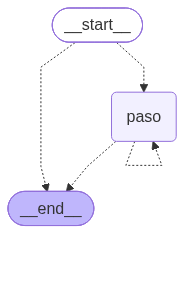

In [10]:
from IPython.display import Image, display

display(Image(euclides.get_graph().draw_mermaid_png()))

`compile` revisa la estructura y devuelve el grafo ejecutable. Comprueba que haya una arista desde `START` y que cada arista salga de un vértice conocido y llegue a uno que existe. No comprueba que todos los nodos sean alcanzables ni que exista un camino a `END`, así que compilar no garantiza que la ejecución termine. El dibujo de `draw_mermaid_png` requiere internet, porque lo genera el servicio mermaid.ink.

El tercer argumento de `add_conditional_edges` declara la imagen de $c$, el conjunto $\{\texttt{paso}, \texttt{END}\}$. Es opcional: sin él el grafo se ejecuta igual. Pero si $c$ está anotada solo como `-> str`, LangGraph no puede deducir a dónde lleva, y la descripción del grafo pierde las aristas desde y hacia `paso`. Una anotación `-> Literal["paso", "__end__"]` también declara la imagen.

In [11]:
constructor = StateGraph(EstadoMCD)
constructor.add_node("paso", paso)
constructor.add_conditional_edges(START, continuar)
constructor.add_conditional_edges("paso", continuar)
sin_imagen = constructor.compile()


def aristas(grafo) -> list[str]:
    return sorted(
        f"{a.source} → {a.target}" + (" (condicional)" if a.conditional else "")
        for a in grafo.get_graph().edges
    )


print("con imagen:", aristas(euclides))
print("sin imagen:", aristas(sin_imagen))
print("resultado sin imagen:", sin_imagen.invoke({"a": 1071, "b": 462}))

con imagen: ['__start__ → __end__ (condicional)', '__start__ → paso (condicional)', 'paso → __end__ (condicional)', 'paso → paso (condicional)']
sin imagen: ['__start__ → __end__ (condicional)']
resultado sin imagen: {'a': 21, 'b': 0}


Sin la imagen, la descripción solo conserva `START → END`: `paso` sigue entre los nodos, pero desconectado, aunque la ejecución da el mismo resultado.

## 7. Ejecución por supersteps

**Definición 1.12 (superstep).** La ejecución avanza en pasos discretos llamados supersteps, numerados desde 0.

- El superstep 0 es el de `START`: escribe la entrada $e$ y produce el estado inicial $s_0$.
- En el superstep $t \ge 1$, se activan los nodos que eligieron las aristas al cerrar el superstep $t - 1$. Cada nodo activo $v$ lee el mismo estado $s_{t-1}$ y calcula su actualización $\varphi_v(s_{t-1})$. Al cerrar el superstep se aplican las actualizaciones; con un solo nodo activo, $s_t = s_{t-1} \oplus \varphi_v(s_{t-1})$.

En este módulo hay un solo nodo activo por superstep. Con varios (módulo 4), todos leen el mismo $s_{t-1}$ y sus actualizaciones se combinan al cerrar el paso.

**Propiedad 1.13.** Una ejecución produce una sucesión de estados $s_0, s_1, s_2, \dots$, un estado por superstep. `stream` con `stream_mode="values"` entrega esa sucesión e `invoke` devuelve su último término. Un superstep en el que ningún nodo escribe no agrega un estado a `stream`; en esta lección todos los nodos escriben.

**Observación.** La entrada también se aplica con $\oplus$: $s_0 = s_\varnothing \oplus e$, donde $s_\varnothing$ es un estado parcial, que tiene en cada clave con reducer su valor inicial (la lista vacía, en una lista) y ninguna otra clave. Como $[\,]$ es neutro para la concatenación, en los grafos de esta lección $s_0$ coincide con la entrada.

In [12]:
for s in euclides.stream({"a": 1071, "b": 462}, stream_mode="values"):
    print(s)

{'a': 1071, 'b': 462}
{'a': 462, 'b': 147}
{'a': 147, 'b': 21}
{'a': 21, 'b': 0}


Es la traza de la sección 1, una memoria por vuelta del `while`:

In [13]:
estados = euclides.stream({"a": 1071, "b": 462}, stream_mode="values")
[(s["a"], s["b"]) for s in estados] == mcd_con_traza(1071, 462)

True

La misma ejecución en el grafo: en cada superstep corre `paso`, el estado nuevo se agrega a la sucesión y $c$ decide con el valor de $b$.

<img src="../../imagenes/diagramas/modulo-1/euclides.svg" alt="El grafo con START, paso y END y las aristas condicionales b ≠ 0 y b = 0. Al lado, los estados s₀ a s₃ aparecen uno por superstep: (1071, 462), (462, 147), (147, 21) y (21, 0); en el superstep 3, b = 0 y la arista elige END" width="640">

Que la traza coincida no es casualidad: la Construcción 1.11 conserva la ejecución.

**Proposición 1.14 (la traducción es exacta).** Sea $D$ un diagrama de flujo en el que ningún ciclo pasa solo por rombos, y sea $G$ el grafo de la Construcción 1.11. Para toda memoria inicial $\sigma_0$, la ejecución de $G$ con entrada $\sigma_0$ recorre los mismos bloques que la de $D$ y en el mismo orden, y sus estados son las memorias de $D$: $s_t = \sigma_t$ en cada superstep $t$ que alcanza a correr. En particular, si $D$ llega al fin después de recorrer $m$ bloques, $G$ llega a `END` en el superstep $m$ con la misma memoria, siempre que `recursion_limit` permita $m + 1$ supersteps (Definición 1.15); y si $D$ no llega al fin, $G$ tampoco llega a `END`.

*Demostración.* Por inducción en $t$. En el superstep 0, `START` escribe la entrada, así que $s_0 = \sigma_0$, y las dos ejecuciones están en el inicio. Supóngase que $s_{t-1} = \sigma_{t-1}$ y que las dos acaban de salir del mismo vértice $v$: el inicio, que corresponde a `START`, o el bloque $v_{t-1}$, que corresponde a su nodo. En $D$, la ejecución sigue la flecha de salida de $v$ y, en cada rombo, la flecha de $p(\sigma_{t-1})$, porque los rombos no cambian la memoria. Ese es el camino que define $c_v$, así que $c_v(s_{t-1})$ es el vértice al que llega $D$. Si es el fin, las dos terminan con la misma memoria. Si es un bloque $w$, en $D$ la memoria pasa a $\sigma_t = T_w(\sigma_{t-1})$, y en $G$ el superstep $t$ ejecuta solo el nodo $w$. Por la Propiedad 1.9, $\oplus$ reemplaza las variables que asigna $w$ y conserva las demás, así que

$$s_t = s_{t-1} \oplus \varphi_w(s_{t-1}) = T_w(s_{t-1}) = \sigma_t.$$

Las dos ejecuciones dan entonces los mismos pasos, y si $D$ llega al fin tras $m$ bloques, $G$ elige `END` al cerrar el superstep $m$. $\square$

Esta es la forma precisa de la idea con que empezó la lección. Un algoritmo que trabaja sobre una memoria de variables tiene un diagrama de flujo (sección 1), y todo diagrama de flujo sin ciclos de solo rombos se traduce en un grafo de LangGraph que lo ejecuta caja por caja, un superstep por caja.

## 8. Newton: otro algoritmo, el mismo grafo

El método de Newton aproxima una raíz de una función derivable $f$ con la iteración

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.$$

Geométricamente, $x_{n+1}$ es el punto donde la recta tangente a la gráfica de $f$ en $(x_n, f(x_n))$ corta el eje $x$. Con $f(x) = x^2 - 2$ y $x_0 = 1$, la primera tangente corta en $x_1 = 3/2$ y la segunda en $x_2 = 17/12$, que ya está a $0{,}0025$ de $\sqrt 2$:

<img src="../../imagenes/figuras/modulo-1/tangentes.svg" alt="La parábola f(x) = x² − 2 con la tangente en x₀ = 1, que corta el eje en x₁ = 1,5, y la tangente en x₁, que lo corta en x₂, casi en raíz de 2" width="600">

Como programa, Newton es un bloque dentro de un `while`, igual que Euclides: mientras $|f(x)| \ge \varepsilon$, se reemplaza $x$ por $x - f(x)/f'(x)$.

In [14]:
EPSILON = 1e-10


def f(x: float) -> float:
    return x**2 - 2


def df(x: float) -> float:
    return 2 * x


def raiz(x: float) -> float:
    while abs(f(x)) >= EPSILON:
        x = x - f(x) / df(x)
    return x


raiz(1.0)

1.4142135623746899

El diagrama de flujo es el de Euclides con otra caja y otro rombo. Al programa se le agrega un contador $n$ de pasos, que no necesita pero sirve para estudiar la ejecución, y la Construcción 1.11 da el mismo grafo que para Euclides: un nodo `paso` y la arista condicional desde `START` y desde `paso`.

| | Euclides | Newton |
|---|---|---|
| esquema | $\{a, b\}$ | $\{x, n\}$ |
| nodo | $(a, b) \mapsto (b,\ a \bmod b)$ | $(x, n) \mapsto \big(x - f(x)/f'(x),\ n + 1\big)$ |
| sigue mientras | $b \ne 0$ | $\lvert f(x) \rvert \ge \varepsilon$ |

In [15]:
class EstadoNewton(TypedDict):
    x: float  # aproximación actual
    n: int  # pasos hechos


def paso_newton(s: EstadoNewton) -> dict:
    """Un paso de Newton: x ← x − f(x)/f′(x)."""
    x = s["x"]
    return {"x": x - f(x) / df(x), "n": s["n"] + 1}


def continuar_newton(s: EstadoNewton) -> str:
    return "paso" if abs(f(s["x"])) >= EPSILON else END


constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso_newton)
constructor.add_conditional_edges(START, continuar_newton, ["paso", END])
constructor.add_conditional_edges("paso", continuar_newton, ["paso", END])
newton = constructor.compile()

for s in newton.stream({"x": 1.0, "n": 0}, stream_mode="values"):
    print(s)

{'x': 1.0, 'n': 0}
{'x': 1.5, 'n': 1}
{'x': 1.4166666666666667, 'n': 2}
{'x': 1.4142156862745099, 'n': 3}
{'x': 1.4142135623746899, 'n': 4}


Cada superstep es un paso de Newton: corre `paso`, el estado nuevo se agrega a la sucesión y $c$ decide con $|f(x_t)|$.

<img src="../../imagenes/diagramas/modulo-1/newton.svg" alt="El grafo con START, paso y END y las aristas condicionales |f(x)| ≥ ε y |f(x)| &lt; ε, desde START y desde paso. Al lado, los estados s₀ a s₄ aparecen uno por superstep; en el superstep 4, |f(x₄)| ≈ 4,5·10⁻¹² &lt; ε y la arista elige END" width="640">

La misma sucesión, con el error $e_n = |x_n - \sqrt{2}|$ y el cociente $e_n / e_{n-1}^2$:

In [16]:
import math

anterior = None
for s in newton.stream({"x": 1.0, "n": 0}, stream_mode="values"):
    e = abs(s["x"] - math.sqrt(2))
    cociente = f"{e / anterior**2:.4f}" if anterior else "—"
    print(f"n = {s['n']}   x = {s['x']:.16f}   e = {e:.1e}   e_n/e_(n-1)² = {cociente}")
    anterior = e

print(f"\n1/(2√2) = {1 / (2 * math.sqrt(2)):.4f}")

n = 0   x = 1.0000000000000000   e = 4.1e-01   e_n/e_(n-1)² = —
n = 1   x = 1.5000000000000000   e = 8.6e-02   e_n/e_(n-1)² = 0.5000
n = 2   x = 1.4166666666666667   e = 2.5e-03   e_n/e_(n-1)² = 0.3333
n = 3   x = 1.4142156862745099   e = 2.1e-06   e_n/e_(n-1)² = 0.3529
n = 4   x = 1.4142135623746899   e = 1.6e-12   e_n/e_(n-1)² = 0.3535

1/(2√2) = 0.3536


En escala logarítmica se ve la diferencia con un método de orden 1, en el que el error solo se divide por una constante en cada paso:

<img src="../../imagenes/figuras/modulo-1/error.svg" alt="Error de Newton en escala logarítmica para n = 0 a 4: 4,1·10⁻¹, 8,6·10⁻², 2,5·10⁻³, 2,1·10⁻⁶ y 1,6·10⁻¹², frente a una recta de orden 1 que divide el error por 2 en cada paso" width="600">

**Teorema (convergencia cuadrática de Newton; resultado clásico).** Si $f$ es de clase $C^2$, $r$ es una raíz con $f'(r) \ne 0$, $x_0$ está suficientemente cerca de $r$ y ningún $e_n$ es cero, entonces

$$\lim_{n \to \infty} \frac{e_{n+1}}{e_n^2} = \left| \frac{f''(r)}{2 f'(r)} \right|.$$

Para $f(x) = x^2 - 2$ y $r = \sqrt{2}$, el límite es $\frac{2}{2 \cdot 2\sqrt{2}} = \frac{1}{2\sqrt{2}} \approx 0{,}3536$, y la tabla se acerca a él desde $n = 3$. El error se aproxima al cuadrado del anterior por una constante, así que su exponente casi se duplica en cada paso. El ejercicio 3 estima ese orden, y la Profundización 1.A, al final de esta sección, demuestra el teorema para $x^2 - 2$ sin la hipótesis de cercanía. `invoke` entrega solo el último término:

In [17]:
newton.invoke({"x": 1.0, "n": 0})

{'x': 1.4142135623746899, 'n': 4}

### Profundización 1.A · Newton para $x^2 - 2$ es el método babilónico

El teorema anterior es local: pide que $x_0$ esté cerca de la raíz. Para $f(x) = x^2 - 2$ se puede demostrar más, con álgebra elemental. El paso de Newton se simplifica a

$$x - \frac{x^2 - 2}{2x} = \frac{1}{2}\left(x + \frac{2}{x}\right),$$

la media aritmética de $x$ y $2/x$. Es el método babilónico (o de Herón) para calcular $\sqrt 2$. Un rectángulo de lados $x$ y $2/x$ tiene área 2; el paso lo cambia por otro de área 2 cuyo lado es el promedio de esos dos lados, y los rectángulos se acercan al cuadrado de lado $\sqrt 2$:

<img src="../../imagenes/figuras/modulo-1/babilonico.svg" alt="Rectángulos de área 2 con lados 1 × 2, 1,5 × 1,333, 1,41667 × 1,41176 y 1,414216 × 1,414211, que se transforman en el cuadrado de lado raíz de 2" width="600">

**Lema 1.A.1.** Si $x > 0$ y $x' = \frac{1}{2}\left(x + \frac{2}{x}\right)$, entonces

$$x' - \sqrt 2 = \frac{(x - \sqrt 2)^2}{2x}.$$

*Demostración.* $x' - \sqrt 2 = \dfrac{x^2 - 2\sqrt 2\, x + 2}{2x} = \dfrac{(x - \sqrt 2)^2}{2x}$. $\square$

**Proposición 1.A.2.** Sean $x_0 > 0$, $x_{n+1} = \frac{1}{2}\left(x_n + \frac{2}{x_n}\right)$ y $e_n = |x_n - \sqrt 2|$. Entonces:

1. $e_{n+1} = \dfrac{e_n^2}{2 x_n}$ para todo $n \ge 0$;
2. $x_n \ge \sqrt 2$ para todo $n \ge 1$, y $(x_n)_{n \ge 1}$ es decreciente;
3. $x_n \to \sqrt 2$ y, si ningún $e_n$ es cero, $e_{n+1}/e_n^2 \to 1/(2\sqrt 2)$.

*Demostración.* Cada $x_n$ es positivo, porque es el promedio de dos números positivos. (1) y la primera parte de (2) salen del Lema 1.A.1: su lado derecho es mayor o igual que cero, así que $x_{n+1} \ge \sqrt 2$ y $e_{n+1} = x_{n+1} - \sqrt 2 = e_n^2 / (2x_n)$. Para $n \ge 1$, $x_{n+1} - x_n = \dfrac{2 - x_n^2}{2x_n} \le 0$. (3) Una sucesión decreciente y acotada inferiormente converge. Su límite $L$ cumple $L \ge \sqrt 2$ y $L = \frac{1}{2}(L + 2/L)$, es decir, $L^2 = 2$, así que $L = \sqrt 2$. Por (1), $e_{n+1}/e_n^2 = 1/(2x_n) \to 1/(2\sqrt 2)$. $\square$

La convergencia es global: vale para todo $x_0 > 0$, no solo cerca de la raíz. Con $x_0$ racional ningún $e_n$ es cero, porque cada $x_n$ es racional y $\sqrt 2$ no lo es. La constante $1/(2\sqrt 2)$ es la del teorema, y (1) explica la tabla de esta sección: sus cocientes son exactamente $1/(2x_{n-1})$, es decir, $1/2$, $1/3$, $6/17 \approx 0{,}3529$ y $204/577 \approx 0{,}3536$.

**Proposición 1.A.3.** Si $x_0 = 1$, cada iterada es una fracción $x_n = p_n / q_n$, con $p_0 = q_0 = 1$ y

$$p_{n+1} = p_n^2 + 2q_n^2, \qquad q_{n+1} = 2 p_n q_n,$$

y $p_n^2 - 2q_n^2 = 1$ para $n \ge 1$. En consecuencia, $|f(x_n)| = 1/q_n^2$ para todo $n \ge 0$.

*Demostración.* Con $x = p/q$, $\frac{1}{2}\left(\frac{p}{q} + \frac{2q}{p}\right) = \frac{p^2 + 2q^2}{2pq}$, y $(p^2 + 2q^2)^2 - 2(2pq)^2 = (p^2 - 2q^2)^2$. Como $p_0^2 - 2q_0^2 = 1 - 2 = -1$, el invariante vale $1$ desde $n = 1$. Por último, $f(p/q) = (p^2 - 2q^2)/q^2$, cuyo valor absoluto es $1/q^2$. $\square$

Los pares $(p_n, q_n)$ son soluciones de la ecuación de Pell $p^2 - 2q^2 = 1$: $(3, 2)$, $(17, 12)$, $(577, 408)$ y $(665857, 470832)$.

**Corolario 1.A.4.** En aritmética exacta y con $\varepsilon = 10^{-10}$, el grafo `newton` llega a `END` en el primer $n$ con $q_n > 10^5$. Como $q_3 = 408$ y $q_4 = 470832$, eso ocurre en el superstep 4, y el menor `recursion_limit` que alcanza es 5. Se predice sin ejecutar; la sección 9 lo confirma.

El mismo grafo `newton` corre en $\mathbb{Q}$ si la entrada es una `Fraction`:

In [18]:
from fractions import Fraction

for s in newton.stream({"x": Fraction(1), "n": 0}, stream_mode="values"):
    p, q = s["x"].numerator, s["x"].denominator
    print(f"n = {s['n']}   x = {p}/{q}   p² − 2q² = {p**2 - 2 * q**2:2d}   |f(x)| = 1/{q**2}")

n = 0   x = 1/1   p² − 2q² = -1   |f(x)| = 1/1
n = 1   x = 3/2   p² − 2q² =  1   |f(x)| = 1/4
n = 2   x = 17/12   p² − 2q² =  1   |f(x)| = 1/144
n = 3   x = 577/408   p² − 2q² =  1   |f(x)| = 1/166464
n = 4   x = 665857/470832   p² − 2q² =  1   |f(x)| = 1/221682772224


No hubo que cambiar el grafo: `paso_newton` y `continuar_newton` solo usan $+$, $-$, $\times$, $/$ y una comparación, que `Fraction` calcula sin redondeo. La anotación `x: float` no lo impide, porque el `TypedDict` no valida tipos (Observación de la sección 3). En esta ejecución en punto flotante, $x_4$ resulta ser exactamente el flotante más cercano a $665857/470832$. No es un hecho general: los redondeos de $x_2$ y $x_3$ podrían haberlo movido. La celda siguiente lo comprueba:

In [19]:
float(Fraction(665857, 470832)) == newton.invoke({"x": 1.0, "n": 0})["x"]

True

**Observación 1.A.5 (Newton y Euclides).** El grafo `con_cocientes` de la sección 5 calcula la fracción continua de cada iterada:

In [20]:
for s in newton.stream({"x": Fraction(1), "n": 0}, stream_mode="values"):
    p, q = s["x"].numerator, s["x"].denominator
    cocientes = con_cocientes.invoke({"a": p, "b": q, "cocientes": []})["cocientes"]
    print(f"x_{s['n']} = {p}/{q} = {cocientes}")

x_0 = 1/1 = [1]


x_1 = 3/2 = [1, 2]
x_2 = 17/12 = [1, 2, 2, 2]
x_3 = 577/408 = [1, 2, 2, 2, 2, 2, 2, 2]
x_4 = 665857/470832 = [1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


La fracción continua de $\sqrt 2$ es $[1; 2, 2, 2, \dots]$, y cada iterada la trunca: $x_n = [1; 2, \dots, 2]$ con $2^n - 1$ doses. En cada paso la cantidad de doses pasa de $k$ a $2k + 1$, así como los dígitos correctos casi se duplican. La razón es que la recurrencia de la Proposición 1.A.3 eleva al cuadrado en $\mathbb{Z}[\sqrt 2]$:

$$p_{n+1} + q_{n+1}\sqrt 2 = p_n^2 + 2q_n^2 + 2p_n q_n \sqrt 2 = (p_n + q_n\sqrt 2)^2,$$

así que $p_n + q_n \sqrt 2 = (1 + \sqrt 2)^{2^n}$. Las fracciones que truncan la fracción continua de $\sqrt 2$ se llaman *convergentes*, y la convergente con $k$ doses cumple $p + q\sqrt 2 = (1 + \sqrt 2)^{k+1}$ (resultado clásico). Con $k + 1 = 2^n$ queda $k = 2^n - 1$.

## 9. Terminación

Un `while` puede no terminar, y un grafo con un ciclo tampoco. LangGraph pone un tope a la cantidad de supersteps, y una variante prueba que el tope no hace falta. Euclides y Newton muestran los dos casos: el primero termina con toda entrada; el segundo, no siempre.

**Definición 1.15 (`recursion_limit`).** `recursion_limit` es la cantidad máxima de supersteps de una ejecución, contando el de `START`. Se pasa en la configuración: `invoke(entrada, {"recursion_limit": L})`. Si la ejecución necesita más, LangGraph la detiene con `GraphRecursionError`. En langgraph 1.2.17 vale 10 007 por defecto. El valor está en `langgraph/_internal/_config.py` y se cambia con la variable de entorno `LANGGRAPH_DEFAULT_RECURSION_LIMIT`.

**Definición 1.16 (variante).** Una variante de un grafo es una función $V : S \to \mathbb{N}$ que baja estrictamente en cada superstep en que corre un nodo: $V(s_t) < V(s_{t-1})$ para todo $t \ge 1$.

La idea es de R. W. Floyd (*Assigning meanings to programs*, 1967), que la formuló para diagramas de flujo: un natural no puede bajar para siempre. Floyd usó conjuntos bien ordenados en general; aquí basta $\mathbb{N}$.

**Proposición 1.17.** Para toda entrada con $a_0, b_0 \in \mathbb{N}$, la ejecución de `euclides` usa a lo más $b_0 + 1$ supersteps. En particular, con `recursion_limit` $\ge b_0 + 1$ llega a `END`.

*Demostración.* $V(s) = s(b)$ es una variante. Si en el superstep $t$ corre `paso`, es porque $c$ vio $b_{t-1} \ne 0$, y entonces $b_t = a_{t-1} \bmod b_{t-1} < b_{t-1}$. Una sucesión estrictamente decreciente de naturales que empieza en $b_0$ tiene a lo más $b_0 + 1$ términos, así que `paso` corre a lo más $b_0$ veces. Con el superstep de `START`, son a lo más $b_0 + 1$. $\square$

La cota es pobre: para $(1071, 462)$ permite 463 supersteps y se usan 4. El ejercicio 7 la mejora hasta una cota logarítmica, con el teorema de Lamé. Para Newton no hay variante, y la ejecución puede no terminar.

**Proposición 1.18.** Sean $\varepsilon > 0$, $L$ el valor de `recursion_limit` y $(x_n)$ las iteradas que calcula el grafo `newton`, en punto flotante. Supóngase que $f'(x_k) \ne 0$ para cada iterada usada en un paso y que todas las evaluaciones de $f$ y $f'$ dan números finitos.

1. Si existe $n \ge 0$ con $|f(x_n)| < \varepsilon$ y el menor de ellos cumple $n + 1 \le L$, la ejecución llega a `END` en el superstep $n$.
2. Si no existe tal $n$, la ejecución nunca llega a `END`: `recursion_limit` la detiene con `GraphRecursionError`.

*Demostración.* La arista condicional desde `START` evalúa $c$ en $s_0$, y después de cada paso $c$ se evalúa en el estado nuevo. (1) Si $n$ es el menor índice con $|f(x_n)| < \varepsilon$, $c$ elige `paso` en $s_0, \dots, s_{n-1}$ y `END` en $s_n$. Eso usa los supersteps $0, \dots, n$, que son $n + 1 \le L$. (2) Las aristas que llegan a `END` son las condicionales, y $c$ elige `END` solo cuando $|f(x_n)| < \varepsilon$. Si eso no ocurre nunca, $c$ elige `paso` en cada superstep hasta superar $L$. $\square$

Con $f(x) = x^2 + 1$ se tiene $|f(x)| \ge 1 > \varepsilon$ para todo $x$ real, así que ese $n$ no existe, y la ejecución se detiene con `GraphRecursionError`:

In [21]:
from langgraph.errors import GraphRecursionError


def construir_newton(g, dg, epsilon=EPSILON, cota=None):
    """Grafo de Newton para g. Con `cota`, llega a END después de a lo más `cota` pasos."""

    def paso(s: EstadoNewton) -> dict:
        x = s["x"]
        return {"x": x - g(x) / dg(x), "n": s["n"] + 1}

    def continuar(s: EstadoNewton) -> str:
        sigue = abs(g(s["x"])) >= epsilon
        if cota is not None:
            sigue = sigue and s["n"] < cota
        return "paso" if sigue else END

    constructor = StateGraph(EstadoNewton)
    constructor.add_node("paso", paso)
    constructor.add_conditional_edges(START, continuar, ["paso", END])
    constructor.add_conditional_edges("paso", continuar, ["paso", END])
    return constructor.compile()


sin_raiz = construir_newton(lambda x: x**2 + 1, lambda x: 2 * x)
try:
    sin_raiz.invoke({"x": 0.5, "n": 0}, {"recursion_limit": 100})
except GraphRecursionError as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])

GraphRecursionError

 → Recursion limit of 100 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


Para $x^2 - 2$ desde $x_0 = 1$ hay 4 pasos de Newton más el superstep de `START`, así que el mínimo es $L = 5$:

In [22]:
for limite in (4, 5):
    try:
        newton.invoke({"x": 1.0, "n": 0}, {"recursion_limit": limite})
        print(f"recursion_limit = {limite}: llega a END")
    except GraphRecursionError:
        print(f"recursion_limit = {limite}: GraphRecursionError")

recursion_limit = 4: GraphRecursionError


recursion_limit = 5: llega a END


Los cinco supersteps de esta ejecución frente a los dos límites:

<img src="../../imagenes/diagramas/modulo-1/limite.svg" alt="Cinco supersteps en fila, 0 START y 1 a 4 paso, seguidos de END. Con recursion_limit = 4 caben del 0 al 3 y el 4 excede el límite; con recursion_limit = 5 caben los cinco y la ejecución llega a END" width="600">

`recursion_limit` corta la ejecución con un error. Para que una ejecución sin variante termine por sí misma, la cota tiene que estar en la arista.

**Proposición 1.19.** Sea $N \in \mathbb{N}$ con $N \ge 1$, y sea

$$c_N(s) = \begin{cases} \texttt{paso} & \text{si } |f(s(x))| \ge \varepsilon \text{ y } s(n) < N, \\ \texttt{END} & \text{si no.} \end{cases}$$

Supóngase que la entrada tiene $n = 0$, que $f'(x_k) \ne 0$ para cada iterada usada en un paso, que todas las evaluaciones de $f$ y $f'$ dan números finitos y que `recursion_limit` $\ge N + 1$. Entonces la ejecución llega a `END` después de a lo más $N$ pasos de Newton, es decir, en a lo más $N + 1$ supersteps.

*Demostración.* Cada superstep de `paso` aumenta $n$ en 1, así que después de $k$ pasos $s_k(n) = k$, y $N - s(n)$ funciona como variante. Si $c_N$ no eligió `END` antes, en $s_N$ vale $s_N(n) = N$ y $c_N$ elige `END`. Eso ocurre en el superstep $N$, el número $N + 1$ contando el de `START`, y la hipótesis sobre `recursion_limit` asegura que se alcanza. $\square$

In [23]:
acotado = construir_newton(lambda x: x**2 + 1, lambda x: 2 * x, cota=50)
final = acotado.invoke({"x": 0.5, "n": 0})

print(final)
print("|f(x)| < ε:", abs(final["x"] ** 2 + 1) < EPSILON)

{'x': -0.8707527744354187, 'n': 50}
|f(x)| < ε: False


Llegar a `END` no implica converger. Con la cota, el estado final tiene que revisarse: aquí $n = N = 50$ y $|f(x_{50})| \ge \varepsilon$.

Las dos formas de terminar para $x^2 + 1$, lado a lado:

<img src="../../imagenes/diagramas/modulo-1/terminacion.svg" alt="A la izquierda, sin cota: c elige paso siempre, la arista a END nunca se usa y recursion_limit corta con GraphRecursionError. A la derecha, con cota N = 50: c_N elige END cuando n = N y el estado final no es raíz" width="560">

### Profundización 1.B · Lo que ejecuta `compile`: Pregel y canales

Las Definiciones 1.10 y 1.12 dicen qué hace una ejecución. Esta profundización muestra cómo la implementa LangGraph. `compile` traduce el grafo a un programa de **Pregel**, el modelo de cómputo que Google diseñó para procesar grafos grandes (Malewicz et al., *Pregel: a system for large-scale graph processing*, SIGMOD 2010). Pregel sigue el modelo *bulk synchronous parallel* de Valiant (*A bridging model for parallel computation*, 1990): el cómputo avanza en pasos sincronizados, y de ahí viene el nombre superstep.

In [24]:
print([clase.__name__ for clase in type(newton).__mro__[:2]])
{clave: type(canal).__name__ for clave, canal in newton.channels.items()}

['CompiledStateGraph', 'Pregel']


{'x': 'LastValue',
 'n': 'LastValue',
 '__start__': 'EphemeralValue',
 '__pregel_tasks': 'Topic',
 'branch:to:paso': 'EphemeralValue'}

**Definición 1.B.1 (canal).** Un canal guarda un valor y un número de versión. Al cerrar un superstep, si recibió escrituras en ese paso, las combina con su función de actualización y sube de versión, aunque el valor nuevo sea igual al anterior. Un canal efímero que se vacía también sube de versión. El grafo de Newton tiene dos clases de canales:

- **de estado**, uno por clave del esquema (`x`, `n`), cuya función de actualización es el reducer de la clave (sección 5);
- **de disparo**, que no son parte del estado: `__start__`, donde `invoke` escribe la entrada, y `branch:to:paso`. Son de tipo `EphemeralValue`: si en un superstep nadie escribe en ellos, al cerrarlo quedan vacíos, y un canal vacío no dispara a ningún actor.

El canal `__pregel_tasks`, de tipo `Topic`, sirve para `Send`, que aparece en el módulo 4.

**Definición 1.B.2 (actor).** Cada nodo $v$ se compila en un actor con tres datos: los canales que lo disparan (`triggers`), los que lee (`channels`) y los que escribe. `START` también es un actor, `__start__`, disparado por el canal del mismo nombre.

In [25]:
{nombre: (actor.triggers, actor.channels) for nombre, actor in newton.nodes.items()}

{'__start__': (['__start__'], '__start__'),
 'paso': (['branch:to:paso'], ['x', 'n'])}

**Propiedad 1.B.3 (las aristas son escrituras).** En `langgraph/graph/state.py` (métodos `attach_edge` y `attach_branch`):

- una arista fija $(v, w)$ con $w \ne \texttt{END}$ agrega al actor $v$ una escritura en `branch:to:w` (`add_edge` con varios orígenes usa otro canal, que no aparece en este módulo);
- una arista condicional desde $v$ agrega al actor $v$ una escritura en el canal `branch:to:` de $c(s)$, con $c$ evaluada en el estado que ya incluye la actualización de $v$. Si $c(s) = \texttt{END}$, no escribe nada.

Las aristas que salen de `START` son del actor `__start__`. `END` no es un actor ni un canal: llegar a `END` es no escribir en ningún canal de disparo.

**Algoritmo 1.B.4 (un superstep).** Según la documentación de la clase `Pregel` (`langgraph/pregel/main.py`), cada superstep tiene tres fases:

1. **Planificar.** Se activan los actores con algún canal de disparo que tiene valor y una versión mayor que la última que el actor vio (`_triggers`, en `langgraph/pregel/_algo.py`; si el actor nunca corrió, basta con que el canal tenga valor). Como los canales de disparo son `EphemeralValue`, eso ocurre cuando alguien escribió en él en el superstep anterior; en el superstep 0, la escritura de la entrada.
2. **Ejecutar.** Los actores activos corren con el estado $s_{t-1}$. Los demás actores del mismo superstep no ven sus escrituras; solo la arista condicional del propio actor las ve (Propiedad 1.B.3).
3. **Actualizar.** Se aplican las escrituras a los canales y suben sus versiones.

Se repite hasta que ningún actor quede activo o se supere `recursion_limit`.

<img src="../../imagenes/diagramas/modulo-1/pregel.svg" alt="Los actores __start__ y paso y los canales __start__, x, n y branch:to:paso. En el superstep 0, __start__ escribe x y n, y c(s₀) = paso escribe en branch:to:paso; en cada superstep siguiente paso lee y escribe x y n, y c escribe en branch:to:paso hasta que elige END y no escribe nada" width="760">

Con esto se precisan tres afirmaciones de la lección:

- *La ejecución termina cuando no queda ningún nodo activo* (Definición 1.10). En el superstep 4, $c(s_4) = \texttt{END}$ no escribe en `branch:to:paso`, así que en el superstep 5 no hay actores activos.
- *El superstep 0 es el de `START`* (Definición 1.12). Es el actor `__start__`, disparado por la escritura de `invoke` en el canal `__start__`; por eso `recursion_limit` lo cuenta.
- *`stream` entrega la sucesión de estados* (Propiedad 1.13). Con `stream_mode="updates"` entrega, en cambio, las actualizaciones $u_t = \varphi(s_{t-1})$ de cada actor, sin el superstep 0, que es interno. Con `stream_mode="debug"`, cada tarea con el canal que la disparó; tampoco aparece el actor `__start__`.

In [26]:
for u in newton.stream({"x": 1.0, "n": 0}, stream_mode="updates"):
    print(u)

{'paso': {'x': 1.5, 'n': 1}}
{'paso': {'x': 1.4166666666666667, 'n': 2}}
{'paso': {'x': 1.4142156862745099, 'n': 3}}
{'paso': {'x': 1.4142135623746899, 'n': 4}}


In [27]:
for evento in newton.stream({"x": 1.0, "n": 0}, stream_mode="debug"):
    if evento["type"] == "task":
        print("superstep", evento["step"], "·", evento["payload"]["name"], "· disparado por", evento["payload"]["triggers"])

superstep

 1 · paso · disparado por ('branch:to:paso',)
superstep 2 · paso · disparado por ('branch:to:paso',)
superstep 3 · paso · disparado por ('branch:to:paso',)
superstep 4 · paso · disparado por ('branch:to:paso',)


## Resumen

- Un algoritmo es un grafo. Su **diagrama de flujo** tiene bloques $T : \Sigma \to \Sigma$, que cambian una memoria, y decisiones $p : \Sigma \to \{\mathsf V, \mathsf F\}$, que eligen la flecha. Ejecutarlo produce la sucesión de memorias $\sigma_0, \sigma_1, \dots$, una por bloque. Con secuencia, selección e iteración se arma cualquier diagrama de flujo (Böhm–Jacopini).
- LangGraph escribe el mismo grafo con otros nombres. La memoria es el **estado**, un elemento de $S = \prod_k V_k$ para un **esquema** $(K, (V_k)_{k \in K})$; en Python, un `dict` y un `TypedDict`, que no valida tipos. Un bloque es un **nodo** $\varphi : S \to U$, que devuelve una actualización parcial calculada con un solo estado, como una asignación simultánea. El inicio y el fin son `START` y `END`.
- $s \oplus u$ aplica el reducer de cada clave de $\operatorname{dom}(u)$. Por defecto el valor nuevo reemplaza al anterior, y entonces $s \oplus \varphi(s) = T(s)$. Con `operator.add` la clave acumula: los cocientes de Euclides forman la fracción continua. Cada clave es un canal, `LastValue` o `BinaryOperatorAggregate`.
- Los rombos no son vértices: se vuelven **aristas condicionales** $c : S \to V \setminus \{\texttt{START}\}$, una desde cada vértice cuya flecha llega al rombo. Un `while` necesita la arista condicional desde `START`; la arista fija `START → paso` es un `do … while`. `add_conditional_edges` puede recibir la imagen de $c$, y `compile` revisa la estructura, pero no garantiza que la ejecución termine.
- La ejecución avanza en **supersteps**: el 0 escribe la entrada y, con un nodo activo, $s_t = s_{t-1} \oplus \varphi(s_{t-1})$. `stream(..., stream_mode="values")` entrega la sucesión de estados e `invoke`, su último término. La traducción de un diagrama de flujo es exacta: $s_t = \sigma_t$ (Proposición 1.14).
- Newton es el mismo grafo con otro nodo. Para $x^2 - 2$ es el método babilónico: converge desde todo $x_0 > 0$ con $e_{n+1} = e_n^2 / (2x_n)$, y desde $x_0 = 1$ sus iteradas resuelven $p^2 - 2q^2 = 1$, lo que predice los 4 pasos antes de ejecutar, y son convergentes de la fracción continua de $\sqrt 2$ (Profundización 1.A).
- Una **variante** prueba que un ciclo termina, como $b$ en Euclides. Sin variante, un ciclo puede no terminar: `recursion_limit` acota los supersteps, `START` incluido, y vale 10 007 por defecto. Una cota en la arista garantiza llegar a `END`, pero no la convergencia.
- `compile` produce un programa de Pregel: cada nodo es un actor que se dispara con su canal `branch:to:v`, y cada arista es una escritura en ese canal. `END` no escribe nada (Profundización 1.B).

## Ejercicios

**Ejercicio 1 (bisección).** Expresar el método de bisección como grafo: un estado con claves $a$, $b$ y $n$ que cumple $f(a)\,f(b) \le 0$, un nodo que reemplaza $a$ o $b$ por el punto medio y una arista condicional que termina cuando $b - a < \varepsilon$. Probarlo con $f(x) = x^2 - 2$ en $[1, 2]$ y determinar cuántos pasos hace.

*Pista:* el invariante $f(a)\,f(b) \le 0$ decide qué extremo se reemplaza. Como en Euclides, la condición es la de un `while`.

<details>
<summary>Solución</summary>

```python
class EstadoBiseccion(TypedDict):
    a: float
    b: float
    n: int


def biseccion(s: EstadoBiseccion) -> dict:
    m = (s["a"] + s["b"]) / 2
    if f(s["a"]) * f(m) <= 0:
        return {"b": m, "n": s["n"] + 1}
    return {"a": m, "n": s["n"] + 1}


def seguir(s: EstadoBiseccion) -> str:
    return "biseccion" if s["b"] - s["a"] >= EPSILON else END


constructor = StateGraph(EstadoBiseccion)
constructor.add_node("biseccion", biseccion)
constructor.add_conditional_edges(START, seguir, ["biseccion", END])
constructor.add_conditional_edges("biseccion", seguir, ["biseccion", END])
bisecar = constructor.compile()

bisecar.invoke({"a": 1.0, "b": 2.0, "n": 0})  # n = 34
```

El nodo devuelve solo el extremo que cambia, y la Propiedad 1.9 conserva el otro. Como Euclides y a diferencia de Newton, la bisección llega a `END` sin cota: después de $n$ pasos, $b - a = 2^{-n}(b_0 - a_0)$, y la ejecución termina en el menor $n$ con $2^{-n}(b_0 - a_0) < \varepsilon$, que es $n = \lfloor \log_2((b_0 - a_0)/\varepsilon) \rfloor + 1$, es decir, $\lfloor \log_2 10^{10} \rfloor + 1 = 34$. Esto vale en aritmética exacta; en punto flotante requiere además que $\varepsilon$ sea mayor que la distancia entre flotantes consecutivos en $[a, b]$.

</details>

**Ejercicio 2 (una clave olvidada).** En `construir_newton` con `cota=50`, cambiar `paso` para que devuelva solo `{"x": ...}`. Predecir qué ocurre con $f(x) = x^2 + 1$ antes de ejecutarlo.

*Pista:* Propiedad 1.9. ¿Qué valor tiene $n$ en cada superstep?

<details>
<summary>Solución</summary>

```python
def paso_sin_n(s: EstadoNewton) -> dict:
    x = s["x"]
    return {"x": x - (x**2 + 1) / (2 * x)}


def continuar_con_cota(s: EstadoNewton) -> str:
    sigue = abs(s["x"] ** 2 + 1) >= EPSILON and s["n"] < 50
    return "paso" if sigue else END


constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso_sin_n)
constructor.add_conditional_edges(START, continuar_con_cota, ["paso", END])
constructor.add_conditional_edges("paso", continuar_con_cota, ["paso", END])

try:
    constructor.compile().invoke({"x": 0.5, "n": 0}, {"recursion_limit": 100})
except GraphRecursionError:
    print("GraphRecursionError: n se quedó en 0")
```

`n` no está en el dominio de la actualización, así que conserva el valor 0 en todos los estados y la condición $s(n) < N$ nunca falla. La Proposición 1.19 supone que cada paso aumenta $n$ en 1: sin esa hipótesis, $N - s(n)$ deja de ser una variante, la cota no actúa y vuelve el `GraphRecursionError`.

</details>

**Ejercicio 3 (orden de convergencia).** Guardar la trayectoria de Newton para $f(x) = x^2 - 2$ en una clave con reducer `operator.add` y estimar el orden de convergencia

$$p_n = \frac{\log(e_{n+1}/e_n)}{\log(e_n/e_{n-1})}, \qquad e_n = |x_n - \sqrt{2}|.$$

*Pista:* la trayectoria completa queda en el estado final, sin necesidad de `stream`.

<details>
<summary>Solución</summary>

```python
class EstadoNewtonTrayectoria(TypedDict):
    x: float
    n: int
    trayectoria: Annotated[list[float], operator.add]


def paso_con_trayectoria(s: EstadoNewtonTrayectoria) -> dict:
    x = s["x"] - f(s["x"]) / df(s["x"])
    return {"x": x, "n": s["n"] + 1, "trayectoria": [x]}


def continuar_trayectoria(s: EstadoNewtonTrayectoria) -> str:
    return "paso" if abs(f(s["x"])) >= EPSILON else END


constructor = StateGraph(EstadoNewtonTrayectoria)
constructor.add_node("paso", paso_con_trayectoria)
constructor.add_conditional_edges(START, continuar_trayectoria, ["paso", END])
constructor.add_conditional_edges("paso", continuar_trayectoria, ["paso", END])
final = constructor.compile().invoke({"x": 1.0, "n": 0, "trayectoria": [1.0]})

e = [abs(x - math.sqrt(2)) for x in final["trayectoria"]]
[math.log(e[i + 1] / e[i]) / math.log(e[i] / e[i - 1]) for i in range(1, len(e) - 1)]
```

Los tres valores, $p_1 \approx 2{,}26$, $p_2 \approx 1{,}98$ y $p_3 \approx 2{,}00$, se acercan a 2: Newton converge con orden 2 hacia una raíz simple. Más iteraciones no mejoran la estimación, porque el error se estanca cerca de la precisión de la máquina ($\sim 10^{-16}$) y $p_n$ deja de ser informativo.

</details>

**Ejercicio 4 ($\sqrt 3$ en aritmética exacta).** Generalizar la Proposición 1.A.3 a $f(x) = x^2 - a$, con $a \in \mathbb{N}$: mostrar que si $x = p/q$ cumple $p^2 - aq^2 = 1$, la iterada siguiente también lo cumple. Comprobarlo con `construir_newton` para $a = 3$ desde $x_0 = 2$, en `Fraction`, y decir en qué superstep llega a `END`.

*Pista:* calcular $(p^2 + aq^2)^2 - a(2pq)^2$.

<details>
<summary>Solución</summary>

```python
from fractions import Fraction

raiz_de_3 = construir_newton(lambda x: x**2 - 3, lambda x: 2 * x)
for s in raiz_de_3.stream({"x": Fraction(2), "n": 0}, stream_mode="values"):
    p, q = s["x"].numerator, s["x"].denominator
    print(s["n"], s["x"], p**2 - 3 * q**2)
```

La iterada siguiente es $\frac{1}{2}\left(\frac{p}{q} + \frac{aq}{p}\right) = \frac{p^2 + aq^2}{2pq}$, y $(p^2 + aq^2)^2 - a(2pq)^2 = (p^2 - aq^2)^2 = 1$. Desde $x_0 = 2 = 2/1$, que ya cumple $4 - 3 = 1$, las iteradas son $7/4$, $97/56$, $18817/10864$ y $708158977/408855776$, todas con $p^2 - 3q^2 = 1$. Como $|f(x_n)| = 1/q_n^2$, el grafo llega a `END` en el primer $n$ con $q_n > 10^5$: $q_3 = 10864$ no alcanza y $q_4 = 408855776$ sí, así que termina en el superstep 4.

</details>

**Ejercicio 5 (los canales de una cadena).** Para el grafo `START → a → b → END` con esquema `{k: int}`, donde `a` suma 1 y `b` multiplica por 10, predecir antes de ejecutar: los canales y su tipo, los `triggers` de cada actor, qué tareas muestra `stream_mode="debug"` y el menor `recursion_limit` con que llega a `END`.

*Pista:* Propiedad 1.B.3. Cada arista fija de un solo origen es una escritura en el canal `branch:to:` de su destino.

<details>
<summary>Solución</summary>

```python
class EstadoK(TypedDict):
    k: int


constructor = StateGraph(EstadoK)
constructor.add_node("a", lambda s: {"k": s["k"] + 1})
constructor.add_node("b", lambda s: {"k": s["k"] * 10})
constructor.add_edge(START, "a")
constructor.add_edge("a", "b")
constructor.add_edge("b", END)
cadena = constructor.compile()

print({clave: type(canal).__name__ for clave, canal in cadena.channels.items()})
print({nombre: actor.triggers for nombre, actor in cadena.nodes.items()})
for evento in cadena.stream({"k": 1}, stream_mode="debug"):
    if evento["type"] == "task":
        print(evento["step"], evento["payload"]["name"], evento["payload"]["triggers"])
for limite in (2, 3):
    try:
        print(limite, cadena.invoke({"k": 1}, {"recursion_limit": limite}))
    except GraphRecursionError:
        print(limite, "GraphRecursionError")
```

Los canales son `k` (`LastValue`); los de disparo `__start__`, `branch:to:a` y `branch:to:b` (`EphemeralValue`), y `__pregel_tasks` (`Topic`). `a` se dispara con `branch:to:a`, que escribe el actor `__start__` por la arista `START → a`, y `b` con `branch:to:b`, que escribe `a`. La arista `b → END` no agrega escrituras, así que después de `b` no queda ningún actor activo. `debug` muestra dos tareas, `a` en el superstep 1 y `b` en el 2, cada una disparada por su canal `branch:to:`; el actor `__start__` no aparece. Son tres supersteps, 0 (`__start__`), 1 (`a`) y 2 (`b`): con `recursion_limit = 2` se lanza `GraphRecursionError` y con 3 el resultado es `{'k': 20}`.

</details>

**Ejercicio 6 (dos nodos en lugar de una caja).** Partir el nodo de Euclides en dos nodos en cadena: `copiar_b`, que hace $a \leftarrow b$, y `resto`, que hace $b \leftarrow a \bmod b$. La arista condicional sale de `START` y de `resto`. Predecir qué devuelve con $(1071, 462)$ antes de ejecutarlo, y después corregir el grafo sin volver a juntar los nodos.

*Pista:* cada nodo corre en su propio superstep y lee el estado que dejó el anterior. ¿Qué vale $a$ cuando corre `resto`? Un programa secuencial correcto necesita una variable auxiliar.

<details>
<summary>Solución</summary>

```python
constructor = StateGraph(EstadoMCD)
constructor.add_node("copiar_b", lambda s: {"a": s["b"]})
constructor.add_node("resto", lambda s: {"b": s["a"] % s["b"]})


def continuar_dos(s: EstadoMCD) -> str:
    return "copiar_b" if s["b"] != 0 else END


constructor.add_conditional_edges(START, continuar_dos, ["copiar_b", END])
constructor.add_edge("copiar_b", "resto")
constructor.add_conditional_edges("resto", continuar_dos, ["copiar_b", END])
constructor.compile().invoke({"a": 1071, "b": 462})  # {'a': 462, 'b': 0}
```

En el superstep 1, `copiar_b` deja $(462, 462)$; en el 2, `resto` lee ese estado y calcula $462 \bmod 462 = 0$. La arista elige `END` y el resultado es $462$, no $21$. Es el mismo error del programa secuencial `a = b; b = a % b`. Por la Proposición 1.14, el grafo hace exactamente lo que hace su diagrama de flujo, errores incluidos. Para corregirlo, como en el programa secuencial, hay que guardar el resto antes de pisar $a$, con una clave auxiliar $r$ y tres nodos:

```python
class EstadoMCDAuxiliar(TypedDict):
    a: int
    b: int
    r: int


constructor = StateGraph(EstadoMCDAuxiliar)
constructor.add_node("guardar_resto", lambda s: {"r": s["a"] % s["b"]})
constructor.add_node("copiar_b", lambda s: {"a": s["b"]})
constructor.add_node("copiar_r", lambda s: {"b": s["r"]})


def continuar_auxiliar(s: EstadoMCDAuxiliar) -> str:
    return "guardar_resto" if s["b"] != 0 else END


constructor.add_conditional_edges(START, continuar_auxiliar, ["guardar_resto", END])
constructor.add_edge("guardar_resto", "copiar_b")
constructor.add_edge("copiar_b", "copiar_r")
constructor.add_conditional_edges("copiar_r", continuar_auxiliar, ["guardar_resto", END])
constructor.compile().invoke({"a": 1071, "b": 462})  # {'a': 21, 'b': 0, 'r': 0}
```

La entrada no trae `r`: la clave no existe hasta que `guardar_resto` la escribe, y nadie la lee antes. El grafo corregido usa tres supersteps por vuelta, y el nodo con la asignación simultánea, uno.

</details>

**Ejercicio 7 (el peor caso de Euclides).** Con el grafo `euclides`, contar los supersteps para cada par $1 \le b < a \le 100$ y encontrar el par que usa más. Después, demostrar el teorema de Lamé (1844): si $a_0 > b_0 \ge 1$ y `paso` corre $k$ veces, entonces $b_0 \ge F_{k+1}$ y $a_0 \ge F_{k+2}$, donde $F_1 = F_2 = 1$ y $F_{j+2} = F_{j+1} + F_j$ son los números de Fibonacci. Deducir una cota logarítmica para los supersteps.

*Pista:* `stream` entrega un estado por superstep. Para la demostración, ir desde la última vuelta hacia atrás, con $a_j = \lfloor a_j / b_j \rfloor\, b_j + b_{j+1}$ y $b_j = a_{j+1}$.

<details>
<summary>Solución</summary>

```python
def supersteps(a: int, b: int) -> int:
    return sum(1 for _ in euclides.stream({"a": a, "b": b}, stream_mode="values"))


conteo = {(a, b): supersteps(a, b) for a in range(2, 101) for b in range(1, a)}
maximo = max(conteo.values())
maximo, [par for par, t in conteo.items() if t == maximo]  # (10, [(89, 55)])
```

El máximo son 10 supersteps (9 pasos), y solo en $(89, 55) = (F_{11}, F_{10})$, dos números de Fibonacci consecutivos.

Sean $(a_j, b_j)$, con $j = 0, \dots, k$, los estados, con $b_k = 0$. Para $j < k$ vale $a_j > b_j \ge 1$: para $j = 0$ por hipótesis, y para $j \ge 1$ porque $a_j = b_{j-1} > a_{j-1} \bmod b_{j-1} = b_j$. Se prueba hacia atrás que $b_j \ge F_{k-j+1}$ y $a_j \ge F_{k-j+2}$. Para $j = k - 1$, $b_{k-1} \ge 1 = F_2$ y $a_{k-1} > b_{k-1}$ da $a_{k-1} \ge 2 = F_3$. Si vale para $j + 1$, entonces $b_j = a_{j+1} \ge F_{k-j+1}$ y, como el cociente $\lfloor a_j / b_j \rfloor$ es al menos 1,

$$a_j \ge b_j + b_{j+1} = a_{j+1} + b_{j+1} \ge F_{k-j+1} + F_{k-j} = F_{k-j+2}.$$

Con $j = 0$ queda $b_0 \ge F_{k+1}$ y $a_0 \ge F_{k+2}$. Para la cota, $F_{j+2} \ge \phi^j$ con $\phi = (1 + \sqrt 5)/2$, por inducción y porque $\phi^2 = \phi + 1$. Entonces $b_0 \ge F_{k+1} \ge \phi^{k-1}$, así que $k \le 1 + \log_\phi b_0$ y los supersteps son a lo más $2 + \log_\phi b_0$. Para $(1071, 462)$ la cota da $14{,}8$ y se usan 4; para $(89, 55)$ da $10{,}3$ y se usan 10. Los pares de Fibonacci consecutivos son el peor caso porque cumplen cada desigualdad con igualdad: todos sus cocientes valen 1, salvo el último, que vale 2.

</details>

**Siguiente:** la lección 2 agrega mensajes, herramientas de SymPy y el modelo de lenguaje.